# [Open in Colab](https://colab.research.google.com/github/dmochow/BME-i9400-2026/blob/main/notebooks/meeting12_nested_cv_calibration_studio.ipynb)

# BME i9400 — Meeting 12
## Studio: Nested Cross-Validation and Calibration

**Fall 2026 · Monday, October 26**

Today you finish the clinical classifier of Meetings 10 and 11 in two respects. First, you estimate
the performance of the whole procedure — including the choice of the penalty — without optimism, by
nested cross-validation. Second, you check whether the model's probabilities can be read as
probabilities, and repair them when they cannot.

**Agenda**

1. The data and the model
2. Choosing $C$ inside one object
3. Nested cross-validation
4. Calibration and the reliability diagram
5. Three models, three calibrations
6. Recalibration
7. Submitting your work

Section 1 is done for you — just read and run it. Sections 2 to 6 contain tasks marked `TODO` that
you are asked to complete. Each task ends with checks that must pass before you move on.

---
## 1 — The data and the model

The data are the 768 women of Meetings 8 to 11, with every impossible zero marked as missing
(Meeting 10). The model is the L1-penalised pipeline of Meeting 11: median imputation,
standardisation, and logistic regression with penalty strength $1/C$.

> One change from Meeting 11: the solver is `saga` instead of `liblinear`. Both minimise the same
> L1-penalised loss, but `liblinear` also penalises the intercept, which pulls strongly penalised
> probabilities toward $0.5$ rather than toward the prevalence. That would distort the calibration
> results of section 5. `saga` leaves the intercept unpenalised, as in Meetings 7 and 11.
>
> `class_weight="balanced"` (Meeting 9, section 7) is available as an option; section 5 uses it.

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
plt.rcParams.update({"font.size": 12, "figure.dpi": 110})

URL = "https://raw.githubusercontent.com/dmochow/BME-i9400-2026/main/data/diabetes.csv"
df  = pd.read_csv(URL)
measured = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df[measured] = df[measured].replace(0, np.nan)
X, y = df.drop(columns="Outcome"), df["Outcome"].values

def clinical_model(C=1.0, class_weight=None):
    # Meeting 11's pipeline: impute, standardise, L1-penalised logistic regression with strength 1/C.
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                         LogisticRegression(penalty="l1", C=C, solver="saga", max_iter=5000,
                                            class_weight=class_weight))

Cs    = np.logspace(-2, 1, 14)                                   # Meeting 11's grid
inner = StratifiedKFold(5, shuffle=True, random_state=9400)      # Meeting 11's folds
outer = StratifiedKFold(5, shuffle=True, random_state=12)        # a second, independent partition
print(f"{len(y)} women, {y.sum()} with diabetes (prevalence {y.mean():.3f}); {X.shape[1]} measurements")

768 women, 268 with diabetes (prevalence 0.349); 8 measurements


---
## 2 — Choosing $C$ inside one object

Meeting 11 chose $C$ with a loop: cross-validate every candidate, keep the best. scikit-learn's
**`GridSearchCV`** packages that loop as a single model. Calling `fit(X, y)` on it

1. cross-validates every candidate value on the folds given by `cv`
2. records the best value in `best_params_` and its score in `best_score_`
3. refits the pipeline with the best value to all of `X`, and stores it as `best_estimator_`

> The candidate values are passed as a dictionary, `{"step__parameter": values}`. The name before
> the double underscore is the pipeline step; `make_pipeline` names each step after its class in
> lower case. Here the parameter is `"logisticregression__C"`.
>
> Because the whole selection is now one object with a `fit` method, it can itself be passed to
> `cross_val_score` — which is what section 3 does.

In [18]:
from sklearn.model_selection import GridSearchCV

# --- TODO: a GridSearchCV over the values Cs for clinical_model(), on the folds `inner`, scored by "roc_auc" ---
search = GridSearchCV(
    estimator=clinical_model(),
    param_grid={"logisticregression__C": Cs},
    cv=inner,
    scoring="roc_auc"
)

assert search is not None, "Fill in search."

search.fit(X, y)

assert np.isclose(search.best_score_, 0.8388, atol=0.002), \
    f"best_score_ should match Meeting 11's best CV AUC (about 0.839), got {search.best_score_:.4f}."

C_best = search.best_params_["logisticregression__C"]
kept   = np.sum(search.best_estimator_[-1].coef_ != 0)

print(f"best C = {C_best:.3f}   cross-validated AUC {search.best_score_:.3f}   measurements kept: {kept}")

best C = 0.143   cross-validated AUC 0.839   measurements kept: 5


This reproduces Meeting 11: the best $C$ is about $0.14$, with a cross-validated AUC of $0.839$.
That number is the **largest of 14** cross-validated scores computed on the same five folds, so it is
optimistic: some of its height comes from the particular folds favouring the particular $C$ that was
chosen.

---
## 3 — Nested cross-validation

The remedy is to treat the selection of $C$ as part of the model, and to evaluate the model on data
that the selection never saw. **Nested cross-validation** wraps the search of section 2 in a second,
outer loop:

- the **outer loop** divides the women into 5 folds; each outer fold is held out once
- on the other four outer folds, the **inner loop** — the `GridSearchCV` — chooses $C$ by its own
  5-fold cross-validation and refits with that $C$
- the refitted model is scored on the held-out outer fold, which played no part in choosing $C$ or
  fitting the weights

> The outer score estimates the performance of the **procedure** "choose $C$ by 5-fold CV, then refit".
> Each outer fold may choose a different $C$; that is expected, because each sees different data.
>
> In total, $5 \times (14 \times 5 + 1) = 355$ models are fitted. `cross_validate(..., return_estimator=True)`
> returns the fitted search from each outer fold, so the $C$ it chose can be read from `best_params_`.

In [19]:
from sklearn.model_selection import cross_validate

# --- TODO: cross-validate `search` on the outer folds, scored by "roc_auc", returning the fitted estimators ---
nested = cross_validate(
    search,
    X,
    y,
    cv=outer,
    scoring="roc_auc",
    return_estimator=True
)

assert nested is not None, "Fill in nested."
assert len(nested["test_score"]) == 5 and "estimator" in nested, "Use cv=outer and return_estimator=True."

chosen = [est.best_params_["logisticregression__C"] for est in nested["estimator"]]

print("outer fold   chosen C   held-out AUC")
for k, (c, s) in enumerate(zip(chosen, nested["test_score"]), 1):
    print(f"{k:>10}{c:>11.3f}{s:>15.3f}")

print(f"\nnested CV AUC:          {nested['test_score'].mean():.3f}")
print(f"best of 14 (section 2): {search.best_score_:.3f}")

outer fold   chosen C   held-out AUC
         1      1.194          0.873
         2      0.242          0.840
         3      0.242          0.793
         4      0.143          0.843
         5      3.455          0.825

nested CV AUC:          0.835
best of 14 (section 2): 0.839


The nested estimate is about $0.834$, half a hundredth below the best-of-14 score. On this dataset
the optimism is small, because the cross-validated AUC is nearly flat over a wide range of $C$
(Meeting 11, section 6): choosing among nearly equal candidates gains little from the noise.

The outer folds chose values of $C$ from about $0.24$ to $3.5$, a factor of more than ten, for the
same reason. The
choice of $C$ is unstable; the performance of the procedure that makes the choice is not.

The optimism is not always small. The cell below repeats the comparison on the noise data of
Meeting 11, section 7 — 60 patients, 1,000 noise features, coin-flip labels — with a grid of 24
candidates (the number of selected features $k$, and $C$), with feature selection correctly inside
the pipeline. It takes about half a minute.

In [20]:
# Done for you: best-of-grid versus nested CV when there is nothing to find.
from sklearn.feature_selection import SelectKBest, f_classif

noise_grid = {"selectkbest__k": [1, 2, 5, 10, 20, 50], "logisticregression__C": [0.01, 0.1, 1, 10]}
best_of_grid, nested_noise = [], []
for seed in range(10):
    r  = np.random.default_rng(seed)
    Xn = r.normal(size=(60, 1000)); yn = r.permutation(np.repeat([0, 1], 30))
    gs = GridSearchCV(make_pipeline(SelectKBest(f_classif), LogisticRegression(max_iter=1000)),
                      noise_grid, cv=inner, scoring="roc_auc")
    best_of_grid.append(gs.fit(Xn, yn).best_score_)
    nested_noise.append(cross_val_score(gs, Xn, yn, cv=outer, scoring="roc_auc").mean())
print(f"10 noise datasets, true AUC 0.5:")
print(f"  best of 24 cross-validated scores:  mean {np.mean(best_of_grid):.3f}   (largest {np.max(best_of_grid):.3f})")
print(f"  nested cross-validation:            mean {np.mean(nested_noise):.3f}")

10 noise datasets, true AUC 0.5:
  best of 24 cross-validated scores:  mean 0.596   (largest 0.850)
  nested cross-validation:            mean 0.533


With nothing to find, the best of 24 cross-validated scores averages near $0.6$, and on some datasets
reaches $0.85$; the nested estimates average about $0.53$, close to the true $0.5$. The optimism of selecting the best
configuration grows with the number of configurations tried and shrinks with the amount of data.

> **Which number to report.** The nested CV score, for the procedure. The model that is actually used
> is `search` fitted to all 768 women, as in section 2; nested CV says how well that procedure can be
> expected to do on new women. Reporting the best-of-grid score is the hyperparameter version of
> tuning a threshold on the test set (Meeting 10).

---
## 4 — Calibration and the reliability diagram

The AUC measures **ranking** (Meeting 9): whether women who develop diabetes receive higher
probabilities than women who do not. It is unchanged by any monotone transformation of the
probabilities, so it says nothing about whether a probability of $0.3$ means a 30% risk.

> A model is **calibrated** if, among all women to whom it assigns probability $p$, a fraction $p$
> develop diabetes. Calibration matters whenever the number itself is used: a risk quoted to a
> patient, a threshold set from a cost ratio (Meeting 9), or an expected number of cases in a clinic.

A **reliability diagram** checks calibration:

1. divide the interval $[0, 1]$ into bins — here 10 bins of width $0.1$
2. assign each woman to the bin containing her predicted probability
3. in each non-empty bin, plot the **mean predicted probability** against the **observed fraction**
   of women with diabetes

A calibrated model lies on the diagonal.

The **Brier score** summarises calibration and discrimination together:

$$\text{Brier} = \frac{1}{n}\sum_{i=1}^{n} \left(p_i - y_i\right)^2$$

> It is the mean squared error of the probabilities, treating the label as $0$ or $1$. Lower is
> better. Predicting the prevalence $\pi$ for every woman gives $\pi(1 - \pi)$, which is $0.227$
> here; a useful model must do better than that.

The probabilities must be **out-of-fold**: each woman's probability comes from a model that did not
see her. `cross_val_predict(model, X, y, cv=outer, method="predict_proba")` returns exactly this, one
probability per woman, from the five outer-fold models.

In [21]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss, roc_auc_score

def oof_probability(model):
    # Out-of-fold probability of diabetes for every woman, from the outer folds.
    return cross_val_predict(model, X, y, cv=outer, method="predict_proba")[:, 1]

def reliability(y_true, p, n_bins=10):
    # Mean predicted probability, observed fraction, and count in each non-empty bin of width 1/n_bins.
    # --- TODO: bin index of each probability (np.digitize) ---
    edges = np.linspace(0, 1, n_bins + 1)
    bins = np.digitize(p, edges[1:-1], right=True)

    counts = np.bincount(bins, minlength=n_bins)
    sum_p = np.bincount(bins, weights=p, minlength=n_bins)
    sum_y = np.bincount(bins, weights=y_true, minlength=n_bins)

    nonempty = counts > 0
    ct = counts[nonempty]
    mp = sum_p[nonempty] / ct
    ob = sum_y[nonempty] / ct

    return mp, ob, ct

def brier(y_true, p):
    return np.mean((y_true - p) ** 2)

model_chosen = clinical_model()
model_chosen.set_params(logisticregression__C=0.05)

p_chosen = oof_probability(model_chosen)
mp, ob, ct = reliability(y, p_chosen)

sk_ob, sk_mp = calibration_curve(y, p_chosen, n_bins=10)

assert np.allclose(mp, sk_mp), "Mean predicted probabilities disagree with sklearn's calibration_curve."
assert np.allclose(ob, sk_ob), "Observed fractions disagree with sklearn's calibration_curve."
assert ct.sum() == len(y), "Every woman should be counted in exactly one bin."
assert np.isclose(brier(y, p_chosen), brier_score_loss(y, p_chosen)), "brier() disagrees with brier_score_loss."

print(f"L1 model, C = 0.05:  Brier {brier(y, p_chosen):.3f}   (predicting the prevalence: {brier(y, np.full(len(y), y.mean())):.3f})")
print(f"{'bin mean p':>12}{'observed':>10}{'women':>7}")
for a, b, c in zip(mp, ob, ct):
    print(f"{a:>12.2f}{b:>10.2f}{c:>7d}")

L1 model, C = 0.05:  Brier 0.160   (predicting the prevalence: 0.227)
  bin mean p  observed  women
        0.08      0.02     62
        0.15      0.07    191
        0.25      0.27    135
        0.34      0.38    125
        0.45      0.45     64
        0.55      0.57     54
        0.65      0.74     57
        0.76      0.86     44
        0.84      0.82     33
        0.92      0.67      3


The model chosen in Meeting 11 is close to calibrated. In the middle bins, from $0.25$ to $0.55$, the
observed fraction is within $0.04$ of the mean predicted probability. At the low end the model
overestimates slightly — 191 women assigned about $0.15$, of whom 7% developed diabetes — and between
$0.65$ and $0.75$ it underestimates by about $0.1$. The top bin holds 3 women and carries almost no
information.

> A bin of 20 women with a true risk of $0.8$ has an observed fraction with a standard error of
> $\sqrt{0.8 \times 0.2 / 20} \approx 0.09$. The reliability diagram should be read together with the
> counts.

---
## 5 — Three models, three calibrations

Two choices made earlier in the course change the probabilities without changing the ranking much:

- **Class weights** (Meeting 9, section 7). `class_weight="balanced"` makes the two classes contribute
  equally to the loss, as if the prevalence were 50%. The intercept shifts upward, and every
  probability with it.
- **A strong penalty** (Meeting 11). Shrinking the weights toward zero pulls every woman's log-odds
  toward the intercept, so the probabilities are squeezed toward the prevalence: high risks are
  underestimated and low risks overestimated.

Compute the out-of-fold probabilities for both and compare them with the model of section 4.

In [22]:
# --- TODO: out-of-fold probabilities for clinical_model(C=0.05, class_weight="balanced") and for clinical_model(C=0.012) ---
p_balanced = oof_probability(clinical_model(C=0.05, class_weight="balanced"))
p_strong   = oof_probability(clinical_model(C=0.012))

assert p_balanced is not None and p_strong is not None, "Fill in p_balanced and p_strong."
assert p_balanced.mean() > p_chosen.mean() + 0.05, "The balanced model's probabilities should be higher on average."

models = {"C = 0.05": p_chosen, "C = 0.05, balanced": p_balanced, "C = 0.012": p_strong}
print(f"{'':<22}{'AUC':>7}{'Brier':>8}{'mean p':>9}     (prevalence {y.mean():.3f})")
for name, p in models.items():
    print(f"{name:<22}{roc_auc_score(y, p):>7.3f}{brier(y, p):>8.3f}{p.mean():>9.3f}")

                          AUC   Brier   mean p     (prevalence 0.349)
C = 0.05                0.829   0.160    0.349
C = 0.05, balanced      0.831   0.169    0.456
C = 0.012               0.790   0.190    0.349


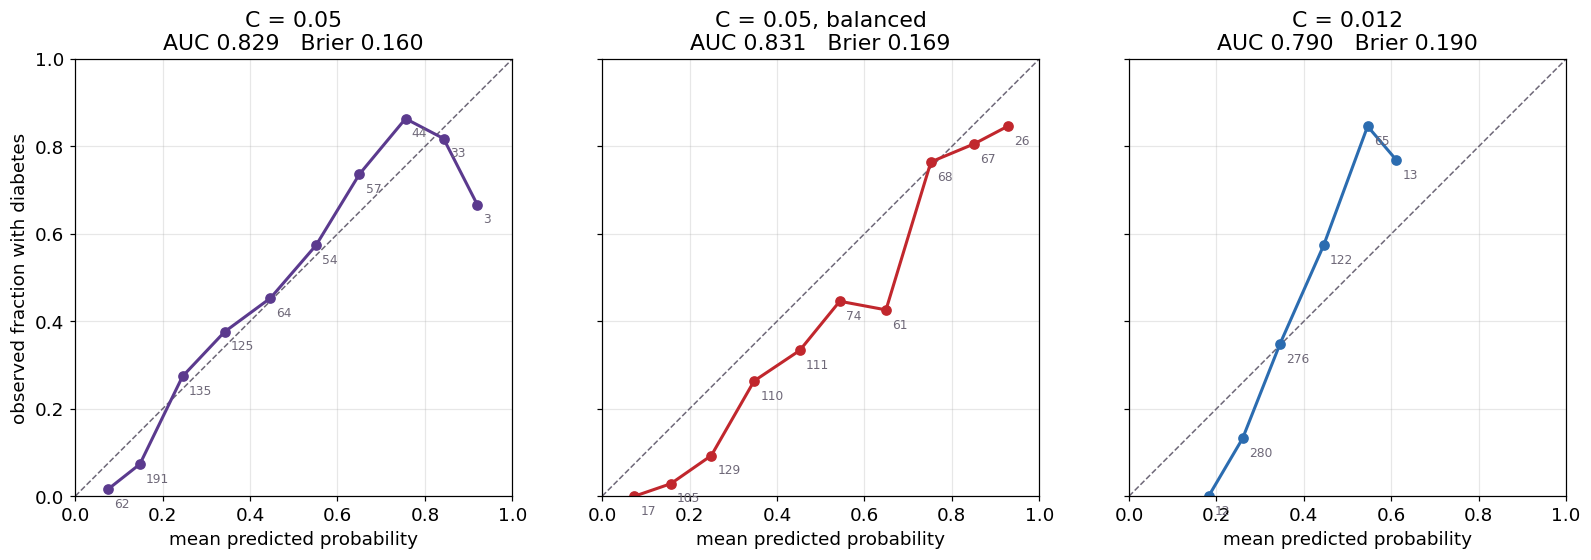

In [23]:
# Done for you: the three reliability diagrams.
fig, axes = plt.subplots(1, 3, figsize=(15, 4.9), sharey=True)
for ax, (name, p), col in zip(axes, models.items(), ["#5b3a8e", "#c1272d", "#2b6cb0"]):
    mp, ob, ct = reliability(y, p)
    ax.plot([0, 1], [0, 1], "--", color="#6e6878", lw=1)
    ax.plot(mp, ob, "o-", color=col, lw=2)
    for a, b, c in zip(mp, ob, ct):
        ax.annotate(str(c), (a, b), textcoords="offset points", xytext=(4, -12), fontsize=8, color="#6e6878")
    ax.set_title(f"{name}\nAUC {roc_auc_score(y, p):.3f}   Brier {brier(y, p):.3f}")
    ax.set_xlabel("mean predicted probability"); ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal"); ax.grid(alpha=0.3)
axes[0].set_ylabel("observed fraction with diabetes")
plt.tight_layout(); plt.show()

The three models have similar AUCs, but different calibrations:

- **Balanced class weights** put every point below the diagonal. A woman assigned $0.25$ has an
  observed risk under $0.1$; the mean predicted probability is about $0.46$ against a prevalence of
  $0.35$. The ranking is that of the unweighted model; the probabilities are too high everywhere.
- **The strong penalty** flattens the curve. No woman is assigned more than about $0.6$, although some
  groups have observed risks above $0.8$; the lowest-risk women are assigned about $0.2$ and almost
  none of them develop diabetes. Its AUC is also lower, because the penalty removed information
  as well as shrinking the scale.

The Brier score separates the three where the AUC does not.

---
## 6 — Recalibration

A model with a good ranking and poor calibration can be repaired without refitting its weights.
**Platt scaling** fits a one-feature logistic regression that maps the model's score to a new
probability:

$$p_{\text{new}} = \sigma\big(a \cdot s + b\big)$$

where $s$ is the model's log-odds score and $a$, $b$ are fitted to labels the model did not see.

> Because $\sigma(a s + b)$ is increasing in $s$ when $a > 0$, recalibration does not change the
> ranking, and the AUC is unchanged up to small differences from refitting.
>
> `CalibratedClassifierCV(model, method="sigmoid", cv=5)` implements Platt scaling with its own
> internal folds: the model is fitted on four of them and $a$, $b$ on the fifth. Wrapped in
> `oof_probability`, the whole recalibrated procedure is evaluated on the outer folds, as in
> section 3.

In [24]:
from sklearn.calibration import CalibratedClassifierCV

# --- TODO: out-of-fold probabilities of the balanced model (C = 0.05), recalibrated by Platt scaling ---
p_recalibrated = oof_probability(
    CalibratedClassifierCV(
        estimator=clinical_model(C=0.05, class_weight="balanced"),
        method="sigmoid",
        cv=inner
    )
)

assert p_recalibrated is not None, "Fill in p_recalibrated."
assert abs(p_recalibrated.mean() - y.mean()) < 0.02, "Recalibrated probabilities should average close to the prevalence."

for name, p in [("balanced", p_balanced), ("balanced, recalibrated", p_recalibrated), ("C = 0.05 (section 4)", p_chosen)]:
    print(f"{name:<26} AUC {roc_auc_score(y, p):.3f}   Brier {brier(y, p):.3f}   mean p {p.mean():.3f}")

balanced                   AUC 0.831   Brier 0.169   mean p 0.456
balanced, recalibrated     AUC 0.829   Brier 0.159   mean p 0.349
C = 0.05 (section 4)       AUC 0.829   Brier 0.160   mean p 0.349


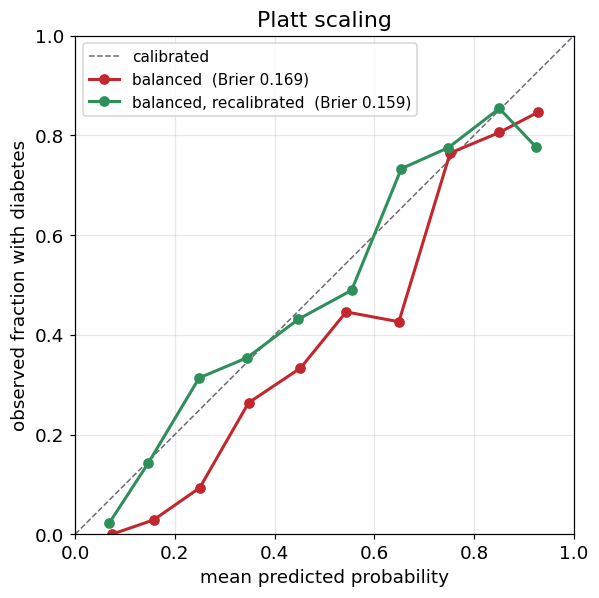

In [25]:
# Done for you: before and after.
fig, ax = plt.subplots(figsize=(6.2, 5.6))
ax.plot([0, 1], [0, 1], "--", color="#6e6878", lw=1, label="calibrated")
for name, p, col in [("balanced", p_balanced, "#c1272d"), ("balanced, recalibrated", p_recalibrated, "#2f8f5b")]:
    mp, ob, ct = reliability(y, p)
    ax.plot(mp, ob, "o-", lw=2, color=col, label=f"{name}  (Brier {brier(y, p):.3f})")
ax.set_xlabel("mean predicted probability"); ax.set_ylabel("observed fraction with diabetes")
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal"); ax.legend(loc="upper left", fontsize=10); ax.grid(alpha=0.3)
ax.set_title("Platt scaling"); plt.tight_layout(); plt.show()

Platt scaling moves the balanced model's curve back onto the diagonal and lowers its Brier score to
that of the unweighted model, with the AUC unchanged. The ranking that class weighting produced was
never the problem; only the scale of its probabilities was.

> Recalibration is fitted to one population. A model calibrated on this cohort, with a prevalence of
> 35%, is not calibrated for a clinic where the prevalence is 10% (Meeting 9, section 6), and must be
> recalibrated on data from that clinic before its probabilities are quoted there.

---
## 7 — Submitting your work

**Due at 11:59 PM EST on Monday, October 26.**

1. `Runtime ▸ Restart session and run all`. Every cell must run without error, and every check must
   pass.
2. `File ▸ Download ▸ Download .ipynb`.
3. Rename the file to `YOUR-GITHUB-USERNAME_meeting12.ipynb` and move it into the `checkins/` folder
   of your clone.
4. Commit in GitHub Desktop, push, and open a pull request.

### Two short questions

Answer in the cell below before you submit.

In [26]:
# One or two sentences each.

# 1. The outer folds of section 3 chose values of C that differ by a factor of more than ten, yet their held-out
#    AUCs are similar. Does this make the nested estimate unreliable? What exactly does it estimate?
Q1 = "No, this does not mean the estimate is unreliable. It shows how well the model performs on new data when we also include the process of choosing the best C."

# 2. The balanced model and the unweighted model have nearly the same AUC. A clinician will tell each woman
#    "your risk of diabetes within five years is X%". Which model's probabilities should be used, and why
#    is the AUC not enough to decide?
Q2 = "I would use the unweighted model or the recalibrated balanced model because their probabilities are more accurate. AUC only tells us how well the model separates the two groups, not if the predicted risk is correct."

for name, ans in [("Q1", Q1), ("Q2", Q2)]:
    assert len(ans.strip()) >= 30, f"{name} looks empty or very short."
print("Answers recorded.")

Answers recorded.
